# 01 · EDA: how Train and Test are structured
**Owner:** Perfect (P1) · **Slice:** Train/Test structure (README §1) · **Feeds decisions:** D-3, D-4, D-5, D-6 in `docs/DECISIONS.md`

Questions: (1) what is one row, and how do two-lender loans look? (2) what do the 4,306 shared customers and 920 shared loans mean? (3) how different is Ghana from Kenya in Test? (4) any duplicates or odd values?

Run from the repo root or `notebooks/`; data must be in `data/raw/` (see README).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
RAW = next(p for p in [Path('data/raw'), Path('../data/raw')] if p.exists()) / 'african-credit-scoring-challenge'
tr = pd.read_csv(RAW/'Train.csv', parse_dates=['disbursement_date','due_date'])
te = pd.read_csv(RAW/'Test.csv',  parse_dates=['disbursement_date','due_date'])
print('Train', tr.shape, '| Test', te.shape)
print('Train ID unique:', tr.ID.is_unique, '| Test ID unique:', te.ID.is_unique, '| ID shared:', len(set(tr.ID) & set(te.ID)))
print('Full-row duplicates in Train:', tr.drop(columns='ID').duplicated().sum())

Train (68654, 16) | Test (18594, 15)
Train ID unique: True | Test ID unique: True | ID shared: 0
Full-row duplicates in Train: 0


## 1. One row = one lender's share of a loan

In [2]:
size = tr.groupby('tbl_loan_id').size()
print('Distinct loans:', len(size), '| rows per loan:', size.value_counts().to_dict())
two = tr[tr.tbl_loan_id.isin(size[size == 2].index)]
chk = two.groupby('tbl_loan_id').agg(customers=('customer_id','nunique'), amounts=('Total_Amount','nunique'),
        dates=('disbursement_date','nunique'), lenders=('lender_id','nunique'),
        labels=('target','nunique'), share=('Lender_portion_Funded','sum'))
print(chk[['customers','amounts','dates','lenders']].max().to_dict(), '<- all 1,1,1,2: same borrower, amount, date; two lenders')
print('Loans where the two lenders disagree on the label:', (chk.labels > 1).sum(), 'of', len(chk))
print('Typical combined lender share:', chk.share.round(2).value_counts().head(3).to_dict(), '(lenders fund only part of a loan)')
print('Default rate: 1-lender loans %.2f%% vs 2-lender loans %.2f%%' % (
    100*tr[tr.tbl_loan_id.isin(size[size==1].index)].target.mean(), 100*two.target.mean()))

Distinct loans: 66520 | rows per loan: {1: 64386, 2: 2134}
{'customers': 1, 'amounts': 1, 'dates': 1, 'lenders': 2} <- all 1,1,1,2: same borrower, amount, date; two lenders
Loans where the two lenders disagree on the label: 2 of 2134
Typical combined lender share: {0.4: 1086, 0.27: 301, 0.32: 168} (lenders fund only part of a loan)
Default rate: 1-lender loans 1.40% vs 2-lender loans 8.29%


**Reading:** a two-lender loan is the same borrower, amount and date split across two lenders, and the label is almost always identical (only 2 disagree). Treat the loan, not the row, as the unit. Two-lender loans also default far more (8.3% vs 1.4% for single-lender loans).

## 2. The overlap between Train and Test

In [3]:
cust_both = set(tr.customer_id) & set(te.customer_id)
loans_both = set(tr.tbl_loan_id) & set(te.tbl_loan_id)
print('Customers in both:', len(cust_both), '| loans in both:', len(loans_both))
print('Share of Test rows whose customer is in Train:', te.customer_id.isin(tr.customer_id).mean().round(3))
print(te.assign(seen=te.customer_id.isin(tr.customer_id)).groupby('country_id').seen.mean().round(3).to_dict(), '<- by country')

a = tr[tr.tbl_loan_id.isin(loans_both)]; b = te[te.tbl_loan_id.isin(loans_both)]
m = a.merge(b, on='tbl_loan_id', suffixes=('_tr','_te'))
print('\nThe 920 shared loans: same customer %.0f%%, same amount %.0f%%, same date %.0f%%, SAME LENDER %.0f%%' % (
    100*(m.customer_id_tr==m.customer_id_te).mean(), 100*(m.Total_Amount_tr==m.Total_Amount_te).mean(),
    100*(m.disbursement_date_tr==m.disbursement_date_te).mean(), 100*(m.lender_id_tr==m.lender_id_te).mean()))
print('Default rate on their Train rows: %.1f%% (overall %.1f%%)' % (100*a.target.mean(), 100*tr.target.mean()))

Customers in both: 4306 | loans in both: 920
Share of Test rows whose customer is in Train: 0.798
{'Ghana': 0.0, 'Kenya': 0.984} <- by country

The 920 shared loans: same customer 100%, same amount 100%, same date 100%, SAME LENDER 0%
Default rate on their Train rows: 8.8% (overall 1.8%)


**Reading:** the 920 shared loans are not duplicated rows. They are the *other lender's share* of a two-lender loan: one row landed in Train, its sibling in Test. Because siblings almost always share the label, **a Test row's answer is effectively known from its Train sibling** (these loans default at 8.8% vs 1.8% overall). That is a leak for validation and for any leaderboard score.

For us, this is handled by grouping: every fold must keep all rows of a customer, hence all rows of a loan, together. `GroupKFold` by `customer_id` does that. Also, 98% of Kenyan Test customers are already in Train, so borrower history is available for Kenya but **not for Ghana (0%)**.

## 3. Kenya vs Ghana in Test

In [4]:
for col in ['lender_id', 'loan_type']:
    unseen = set(te[col]) - set(tr[col])
    rows = te[te[col].isin(unseen)]
    print(f'{col}: Train {tr[col].nunique()} values, Test {te[col].nunique()}; unseen in Train: {sorted(unseen)}')
    print('   rows with an unseen value:', len(rows), '| by country:', rows.country_id.value_counts().to_dict(),
          '| share of Ghana rows: %.0f%%' % (100*len(rows)/(te.country_id=='Ghana').sum()))
print()
print('Ghana loan types:', te[te.country_id=='Ghana'].loan_type.value_counts(normalize=True).round(3).head(3).to_dict())
print('Kenya loan types:', te[te.country_id=='Kenya'].loan_type.value_counts(normalize=True).round(3).head(3).to_dict())
print('Median amount: Train %.0f | Test Kenya %.0f | Test Ghana %.0f (different currencies!)' % (
    tr.Total_Amount.median(), te[te.country_id=='Kenya'].Total_Amount.median(), te[te.country_id=='Ghana'].Total_Amount.median()))
print('Train/Test New borrowers:', (tr.New_versus_Repeat=='New Loan').sum(), (te.New_versus_Repeat=='New Loan').sum())

lender_id: Train 4 values, Test 8; unseen in Train: [296540, 296542, 297182, 297183]
   rows with an unseen value: 3409 | by country: {'Ghana': 3409} | share of Ghana rows: 97%
loan_type: Train 22 values, Test 22; unseen in Train: ['Type_3', 'Type_8']
   rows with an unseen value: 3076 | by country: {'Ghana': 3076} | share of Ghana rows: 87%

Ghana loan types: {'Type_3': 0.862, 'Type_2': 0.127, 'Type_8': 0.01}
Kenya loan types: {'Type_1': 0.904, 'Type_7': 0.039, 'Type_5': 0.02}
Median amount: Train 5249 | Test Kenya 5149 | Test Ghana 3002 (different currencies!)
Train/Test New borrowers: 567 169


**Reading:** Ghana is a different population. About 97% of Ghana rows come from lenders the model has never seen and 87% from loan types it has never seen (Type_3 alone is 86% of Ghana). The model will have almost no direct evidence about these, which is the heart of Part C.

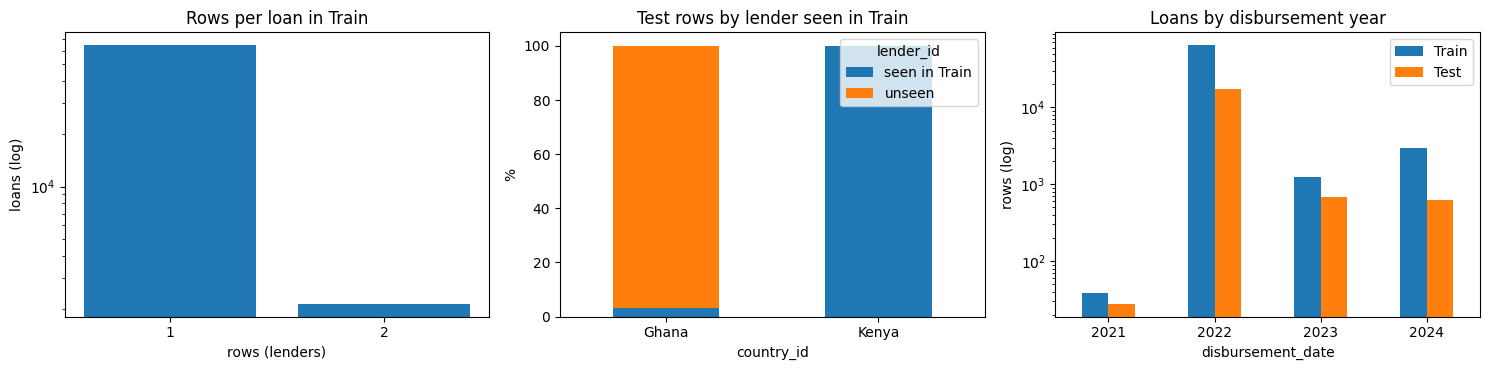

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sz = size.value_counts().sort_index(); ax[0].bar(sz.index.astype(str), sz.values); ax[0].set_yscale('log')
ax[0].set(title='Rows per loan in Train', xlabel='rows (lenders)', ylabel='loans (log)')
ct = pd.crosstab(te.country_id, te.lender_id.isin(tr.lender_id).map({True:'seen in Train', False:'unseen'}), normalize='index')*100
ct.plot.bar(stacked=True, ax=ax[1], rot=0); ax[1].set(title='Test rows by lender seen in Train', ylabel='%')
yr = pd.concat([tr.disbursement_date.dt.year.value_counts().rename('Train'), te.disbursement_date.dt.year.value_counts().rename('Test')], axis=1).sort_index()
yr.plot.bar(ax=ax[2], rot=0, logy=True); ax[2].set(title='Loans by disbursement year', ylabel='rows (log)')
plt.tight_layout(); plt.show()

**Dates:** Test Kenya covers 2021–2024, the same period as Train, so Zindi's Test is a random draw in time, not a "future" set. Ghana runs Nov 2021 to Mar 2023. Our own validation must still include a temporal split, since deployment is always forward in time.

## 4. Odd values and redundancy

In [6]:
print('duration == due_date - disbursement_date:', ((tr.due_date - tr.disbursement_date).dt.days == tr.duration).mean())
print('Amount_Funded == Total_Amount * portion:  ', np.isclose(tr.Amount_Funded_By_Lender, tr.Total_Amount*tr.Lender_portion_Funded, rtol=1e-3).mean())
print('Durations (days):', tr.duration.value_counts().head(6).to_dict())
print('Rows with zero funded amount:', (tr.Amount_Funded_By_Lender <= 0).sum())
big = tr[tr.Total_Amount >= 1e6]
print('Loans >= 1,000,000:', len(big), '| max:', tr.Total_Amount.max(), '| defaults among them:', big.target.sum())
print('99th percentile amount:', tr.Total_Amount.quantile(.99).round(0))
print('Loans per customer:', tr.groupby('customer_id').size().describe().round(1)[['25%','50%','75%','max']].to_dict())

duration == due_date - disbursement_date: 1.0
Amount_Funded == Total_Amount * portion:   1.0
Durations (days): {7: 64973, 14: 1567, 30: 958, 90: 249, 60: 201, 45: 118}
Rows with zero funded amount: 8520
Loans >= 1,000,000: 57 | max: 23000000.0 | defaults among them: 27
99th percentile amount: 119411.0
Loans per customer: {'25%': 2.0, '50%': 6.0, '75%': 14.0, 'max': 208.0}


**Reading:** `due_date` and `Amount_Funded_By_Lender` are exact functions of other columns (drop them, nothing is lost). There are no missing values or duplicate rows. Amounts are very skewed (median about 5k, max 23M), so use a log transform; the 57 loans over 1M include 27 defaults (47%), so they carry signal: keep them rather than deleting. About 8,500 rows show a zero funded amount (a tiny lender share rounded down), so don't divide by it.

## Findings to bring to the Part A session
1. **Unit of analysis is the loan.** Two-lender loans (2,134) share borrower, amount, date and almost always the label. Group by loan/customer in every split. → D-3
2. **The 920 "shared loans" are sibling lender rows, not duplicates**, and they leak the label across Train and Test. Never validate on a row whose sibling is in training. → D-4
3. **Ghana is almost entirely unseen:** 0% of customers, 97% of rows from new lenders, 87% from new loan types. → D-5, Part C
4. **Currency differs** (shillings vs cedis), so convert before comparing amounts. → D-6
5. **Test is not temporal** in Kenya, so our temporal split is stricter than Zindi's, on purpose.